# Photonic PDK validation

Open photonic PDKs ship two things for the same device: a **parametric
geometry cell** driven by design parameters (`gap`, `length`, `radius`,
`width`) and a **foundry-validated compact model** (SAX S-parameters, a
coupling-coefficient lookup table, or a measured spectrum). This notebook
verifies that both are available for the FDTD validation cases and shows the
geometry and the reference data for each.

| Case | Geometry (`gdsfactory`) | Reference data | Source |
| --- | --- | --- | --- |
| 1. Straight waveguide | `ubcpdk.cells.straight` | SAX `waveguides.straight` | UBC SiEPIC EBeam |
| 2. Directional coupler | `ubcpdk.cells.coupler` | κ LUT + measured `opics_ebeam` | UBC / Cornerstone / SiEPIC |
| 3. Ring coupling area | `ubcpdk.cells.ring_single` | κ LUT | UBC / Cornerstone |
| 4. MZI spectrum | `ubcpdk.cells.mzi` | measured spectrum + MZI model | UBC SiEPIC EBeam |
| 5. Ring spectrum | `ubcpdk.cells.ring_single` | measured spectrum | UBC SiEPIC EBeam |
| 6. Bragg spectrum | `gf.components.dbr` | measured spectrum | UBC SiEPIC EBeam |

The compact-model geometry and the simulation geometry use the *same*
parameters, so a `gsim.fdtd` S-parameter extraction can be compared directly
against the model. Only the cloud FDTD run itself is omitted here.

Measured data is fetched from pinned git revisions by
`tests.pdk_validation._fetch` (neither the UBC `.mat` spectra nor the SiEPIC
coupler `.dat` files ship in the published wheels), and the Cornerstone LUTs
are read directly with xarray by `tests.pdk_validation._cspdk`.

In [1]:
import sys
from pathlib import Path

for candidate in (Path.cwd(), Path.cwd().parent):
    if (candidate / "pyproject.toml").is_file() and str(candidate) not in sys.path:
        sys.path.insert(0, str(candidate))

import matplotlib.pyplot as plt
import numpy as np
import ubcpdk

ubcpdk.PDK.activate()

from ubcpdk.models import couplers as dc_models
from ubcpdk.models import waveguides as wg_models

from tests.pdk_validation import _cspdk, _fetch

WAVELENGTHS_UM = np.linspace(1.50, 1.60, 201)
print("active PDK:", ubcpdk.PDK.name)

active PDK: ubcpdk


## Reference data inventory

Both Cornerstone (`cspdk`) and UBC (`ubcpdk`) publish the same strip
directional-coupler and racetrack coupling-coefficient LUTs as xarray tables.
`_cspdk` opens the Cornerstone LUTs directly (the `cspdk` package itself pins a
different gdsfactory release), so the data is available without importing it.

In [2]:

for model in (_cspdk.DIRECTIONAL_COUPLER_STRIP, _cspdk.RACETRACK_STRIP):
    lut = _cspdk.load_lut(model=model)
    print(f"cspdk {model}: shape={lut.shape}")
    for dim in lut.dims:
        print(
            f"    {dim:>10}: {float(lut[dim].min()):g} .. {float(lut[dim].max()):g} um"
        )

for name in ("directional_coupler_strip.nc", "coupler_racetrack_strip.nc"):
    path = Path(ubcpdk.__file__).parent / "models" / name
    with __import__("xarray").open_dataarray(path) as array:
        print(f"ubcpdk {name}: shape={array.shape}")

cspdk directional_coupler_strip: shape=(21, 15, 5, 25, 5)
    wavelength: 1.5 .. 1.6 um
           gap: 0.05 .. 0.75 um
        radius: 5 .. 85 um
      length_x: 0 .. 96 um
      v_offset: 5 .. 85 um
cspdk coupler_racetrack_strip: shape=(21, 21, 13, 15)
    wavelength: 1.5 .. 1.6 um
           gap: 0.05 .. 1.05 um
        radius: 5 .. 245 um
      length_x: 0 .. 28 um
ubcpdk directional_coupler_strip.nc: shape=(21, 15, 5, 25, 5)
ubcpdk coupler_racetrack_strip.nc: shape=(21, 21, 13, 15)


## Case 1 — Straight waveguide

**Geometry** (`ubcpdk.cells.straight`) and **reference model**
(`ubcpdk.models.waveguides.straight`, SAX `straight` with `neff=2.38`,
`ng=4.30`, `loss_dB_cm=3`). The model returns `S(o1,o2)`; its phase slope
gives the group index and its magnitude gives the loss — the quantities the
FDTD run must reproduce.

ports: ['o1', 'o2'] | size: 20.0 1.5 um


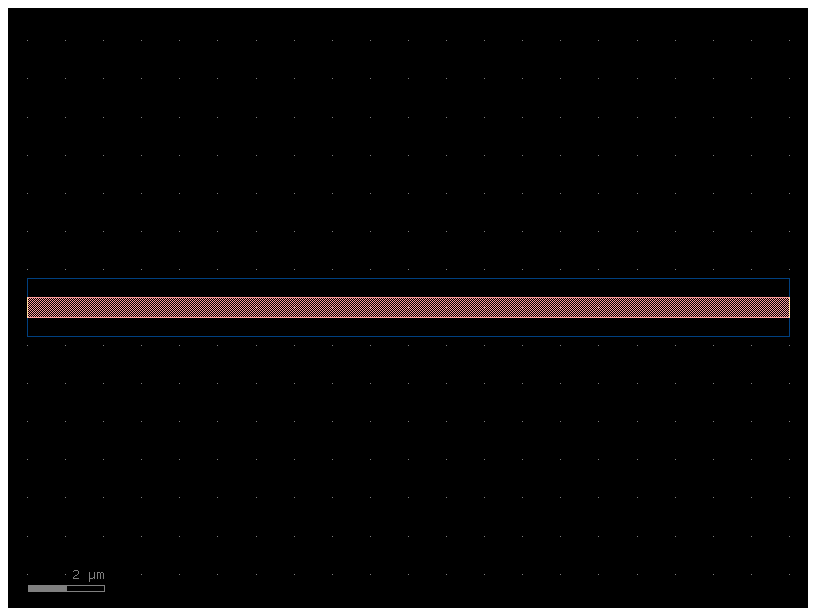

In [3]:
straight = ubcpdk.cells.straight(length=20.0)
print(
    "ports:",
    [port.name for port in straight.ports],
    "| size:",
    straight.xsize,
    straight.ysize,
    "um",
)
straight

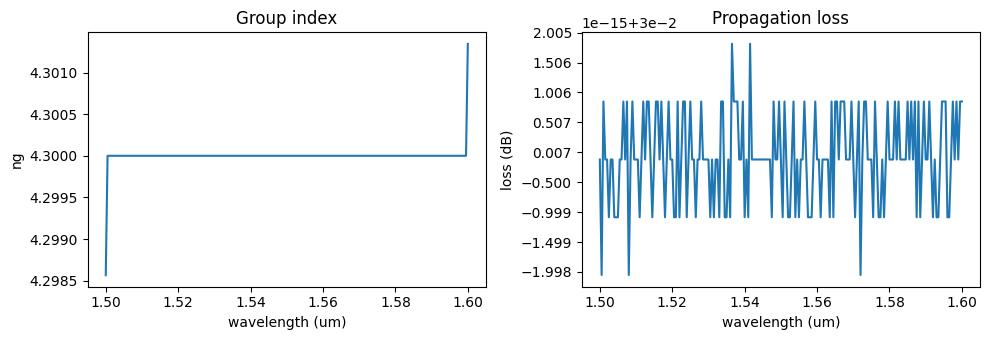

In [4]:
LENGTH_UM = 100.0
s21 = np.asarray(wg_models.straight(wl=WAVELENGTHS_UM, length=LENGTH_UM)[("o1", "o2")])
phase = np.unwrap(np.angle(s21))
ng = -(WAVELENGTHS_UM**2) * np.gradient(phase, WAVELENGTHS_UM) / (2 * np.pi * LENGTH_UM)
loss_db = -20 * np.log10(np.abs(s21))

figure, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(WAVELENGTHS_UM, ng)
axes[0].set(title="Group index", xlabel="wavelength (um)", ylabel="ng")
axes[1].plot(WAVELENGTHS_UM, loss_db)
axes[1].set(title="Propagation loss", xlabel="wavelength (um)", ylabel="loss (dB)")
figure.tight_layout()

## Case 2 — Directional coupler

**Geometry** (`ubcpdk.cells.coupler`) and **reference model**
(`ubcpdk.models.couplers.directional_coupler`), which evaluates the κ LUT over
`wavelength`, `gap`, `radius`, `length_x`, `v_offset` and returns the
through (`tau`) and cross (`j*kappa`) S-parameters at ports `o1..o4`.

ports: ['o1', 'o2', 'o3', 'o4'] | size: 30.0 5.5 um


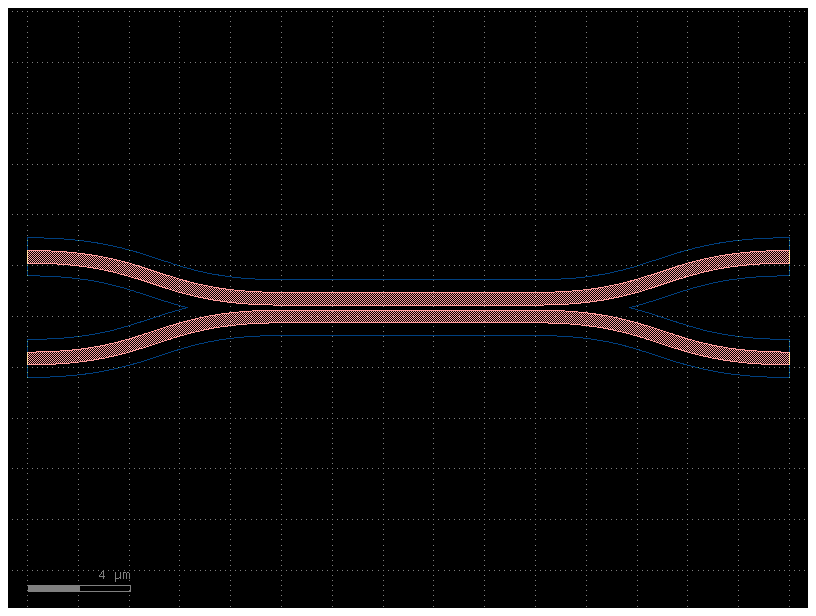

In [5]:
coupler = ubcpdk.cells.coupler(gap=0.2, length=10.0)
print(
    "ports:",
    [port.name for port in coupler.ports],
    "| size:",
    coupler.xsize,
    coupler.ysize,
    "um",
)
coupler

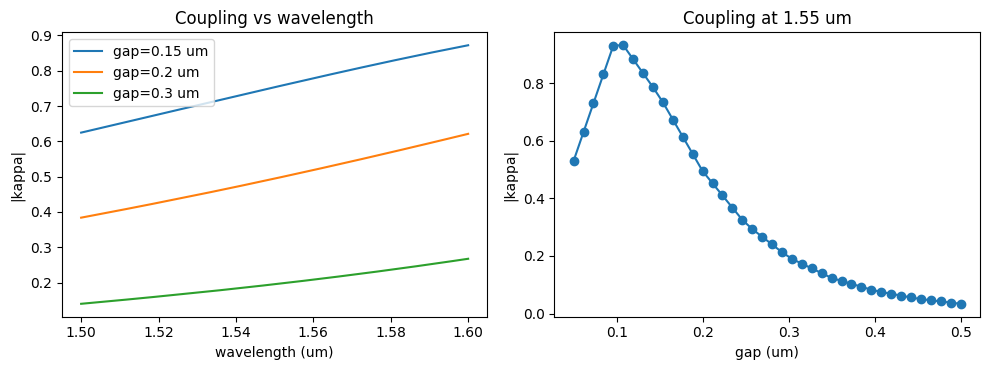

In [6]:
figure, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for gap in (0.15, 0.2, 0.3):
    model = dc_models.directional_coupler(wl=WAVELENGTHS_UM, length=10.0, gap=gap)
    kappa = np.abs(np.asarray(model[("o1", "o3")]))
    axes[0].plot(WAVELENGTHS_UM, kappa, label=f"gap={gap} um")
axes[0].set(title="Coupling vs wavelength", xlabel="wavelength (um)", ylabel="|kappa|")
axes[0].legend()

gaps = np.linspace(0.05, 0.5, 40)
kappa_1550 = np.array(
    [
        float(
            np.abs(
                np.asarray(
                    dc_models.directional_coupler(wl=1.55, length=10.0, gap=gap)[
                        ("o1", "o3")
                    ]
                )
            )
        )
        for gap in gaps
    ]
)
axes[1].plot(gaps, kappa_1550, "o-")
axes[1].set(title="Coupling at 1.55 um", xlabel="gap (um)", ylabel="|kappa|")
figure.tight_layout()

**Measured reference (SiEPIC `opics_ebeam`).** The measured coupler
S-parameters live in `SiEPIC/SiEPIC_EBeam_PDK` (fetched via `_fetch`); each
block holds `(frequency, |S|, phase)`. The `o1`-excited responses are shown
below.

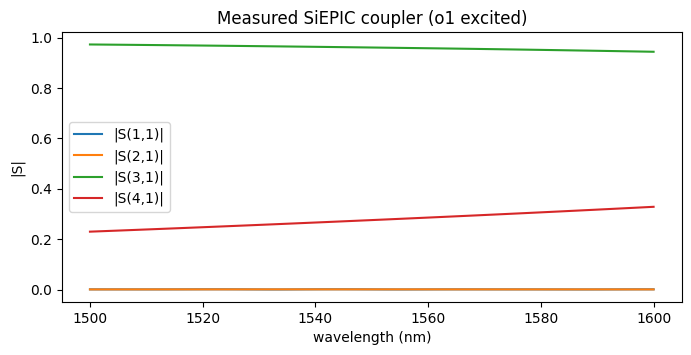

In [7]:
try:
    coupler_dat = _fetch.fetch_siepic_coupler(gap_nm=100, radius_um=10)
    blocks = _fetch.load_siepic_coupler(coupler_dat)
    figure, axis = plt.subplots(figsize=(8, 3.5))
    for (receive, source), values in sorted(blocks.items()):
        if source != 1:
            continue
        wavelength_nm = 299792458.0 / values[:, 0] * 1e9
        axis.plot(wavelength_nm, values[:, 1], label=f"|S({receive},{source})|")
    axis.set(
        title="Measured SiEPIC coupler (o1 excited)",
        xlabel="wavelength (nm)",
        ylabel="|S|",
    )
    axis.legend()
except _fetch.FetchError as error:
    print("Measured coupler unavailable:", error)

## Case 3 — Ring/racetrack coupling area

**Geometry** (`ubcpdk.cells.ring_single`) and **reference model**
(`ubcpdk.models.couplers.coupler_ring_coupling_area`), which evaluates the
racetrack κ LUT over `wavelength`, `gap`, `radius`, `length_x`.

ports: ['o2', 'o1'] | size: 25.5 22.7 um


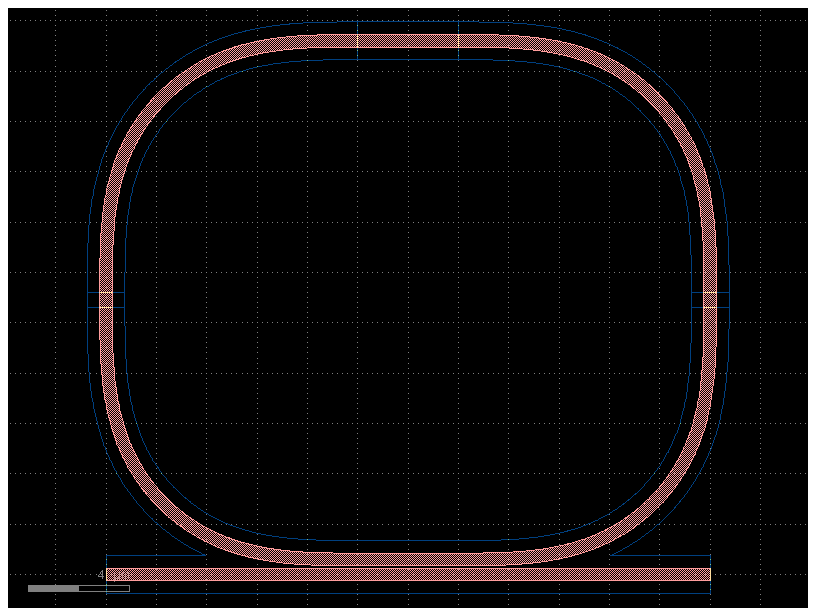

In [8]:
ring = ubcpdk.cells.ring_single(radius=10.0, gap=0.1)
print(
    "ports:",
    [port.name for port in ring.ports],
    "| size:",
    ring.xsize,
    ring.ysize,
    "um",
)
ring

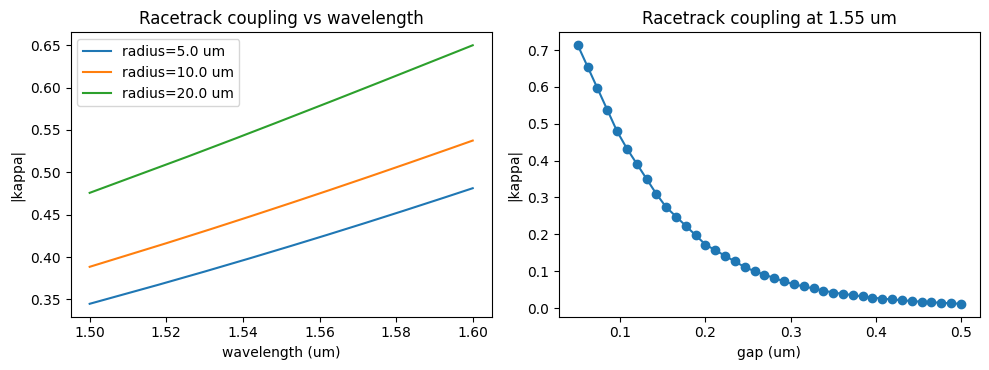

In [9]:
figure, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for radius in (5.0, 10.0, 20.0):
    model = dc_models.coupler_ring_coupling_area(
        wl=WAVELENGTHS_UM, gap=0.1, radius=radius, length_x=2.0
    )
    kappa = np.abs(np.asarray(model[("o1", "o3")]))
    axes[0].plot(WAVELENGTHS_UM, kappa, label=f"radius={radius} um")
axes[0].set(
    title="Racetrack coupling vs wavelength", xlabel="wavelength (um)", ylabel="|kappa|"
)
axes[0].legend()

gaps = np.linspace(0.05, 0.5, 40)
kappa_1550 = np.array(
    [
        float(
            np.abs(
                np.asarray(
                    dc_models.coupler_ring_coupling_area(
                        wl=1.55, gap=gap, radius=10.0, length_x=2.0
                    )[("o1", "o3")]
                )
            )
        )
        for gap in gaps
    ]
)
axes[1].plot(gaps, kappa_1550, "o-")
axes[1].set(title="Racetrack coupling at 1.55 um", xlabel="gap (um)", ylabel="|kappa|")
figure.tight_layout()

## Case 4 — MZI spectrum

**Geometry** (`ubcpdk.cells.mzi`) with the **measured** spectrum as the
validation target, alongside the compact MZI model
(`ubcpdk.simulation.circuits.mzi_spectrum`).

ports: ['o1', 'o2', 'o4', 'o3'] | size: 109.10000000000001 54.5 um


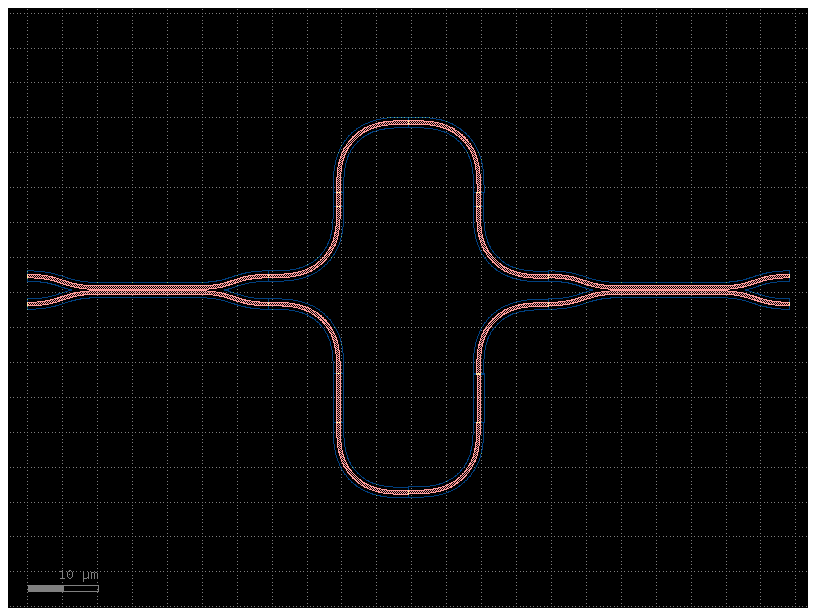

In [10]:
mzi = ubcpdk.cells.mzi(delta_length=10.0)
print(
    "ports:", [port.name for port in mzi.ports], "| size:", mzi.xsize, mzi.ysize, "um"
)
mzi

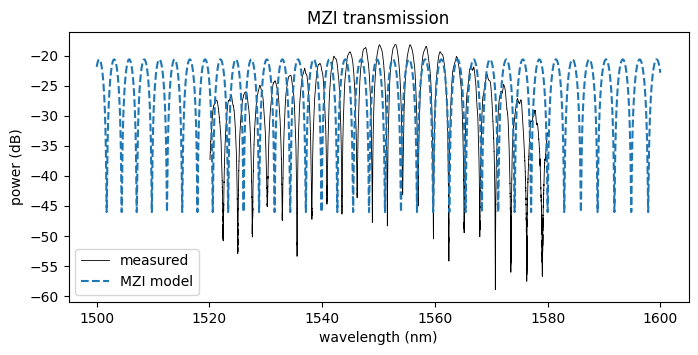

In [11]:
from ubcpdk.simulation.circuits.mzi_spectrum import mzi_spectrum
from ubcpdk.simulation.circuits.waveguide import wavelength_um as mzi_wavelength_um

figure, axis = plt.subplots(figsize=(8, 3.5))
try:
    mzi_dat = _fetch.fetch_ubc(_fetch.UBC_MZI_MAT)
    wavelength_nm, power_dbm = _fetch.load_ubc_spectrum(mzi_dat)
    axis.plot(wavelength_nm, power_dbm, "k", lw=0.6, label="measured")
except _fetch.FetchError as error:
    print("Measured MZI unavailable:", error)

model = mzi_spectrum(L1_um=40, L2_um=255)
axis.plot(mzi_wavelength_um * 1000, 10 * np.log10(model) - 20, "--", label="MZI model")
axis.set(title="MZI transmission", xlabel="wavelength (nm)", ylabel="power (dB)")
axis.legend()

## Case 5 — Ring resonator spectrum

**Geometry** (`ubcpdk.cells.ring_single`) with the **measured** double-ring
spectrum (radius 10 µm, 100 nm gap) as the validation target.

ports: ['o2', 'o1'] | size: 25.5 22.7 um


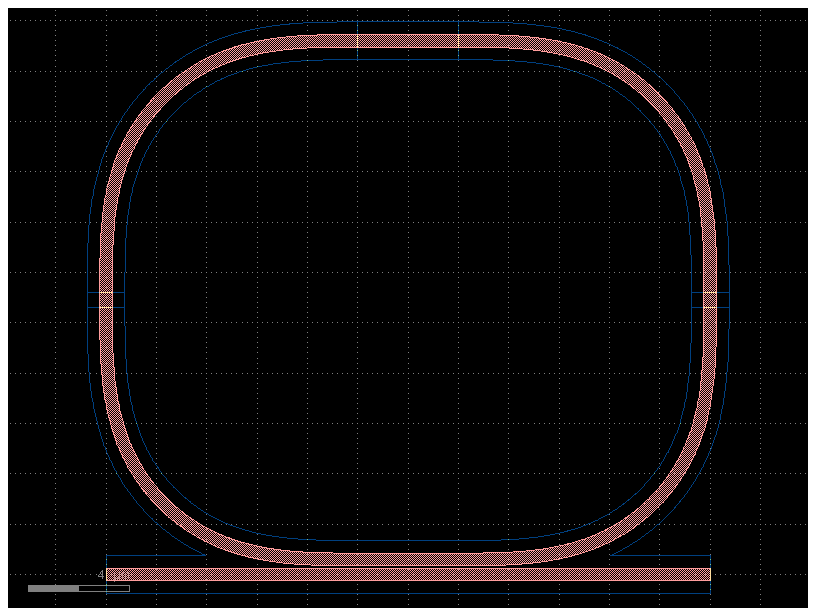

In [12]:
print(
    "ports:",
    [port.name for port in ring.ports],
    "| size:",
    ring.xsize,
    ring.ysize,
    "um",
)
ring

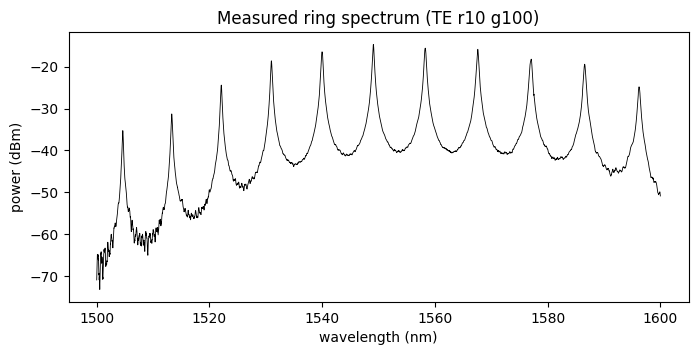

In [13]:
figure, axis = plt.subplots(figsize=(8, 3.5))
try:
    ring_dat = _fetch.fetch_ubc(_fetch.UBC_RING_MAT)
    wavelength_nm, power_dbm = _fetch.load_ubc_spectrum(ring_dat)
    axis.plot(wavelength_nm, power_dbm, "k", lw=0.6)
    axis.set(
        title="Measured ring spectrum (TE r10 g100)",
        xlabel="wavelength (nm)",
        ylabel="power (dBm)",
    )
except _fetch.FetchError as error:
    print("Measured ring unavailable:", error)

## Case 6 — Bragg grating spectrum

**Geometry** (`gf.components.dbr`) with a **measured** Bragg-grating spectrum
as the validation target. The PDK's own compact model for this device is the
Lumerical CML entry `ebeam_bragg_te1550` (shipped as `EBeam.cml`).

ports: ['o1'] | size: 6.38 1.6 um


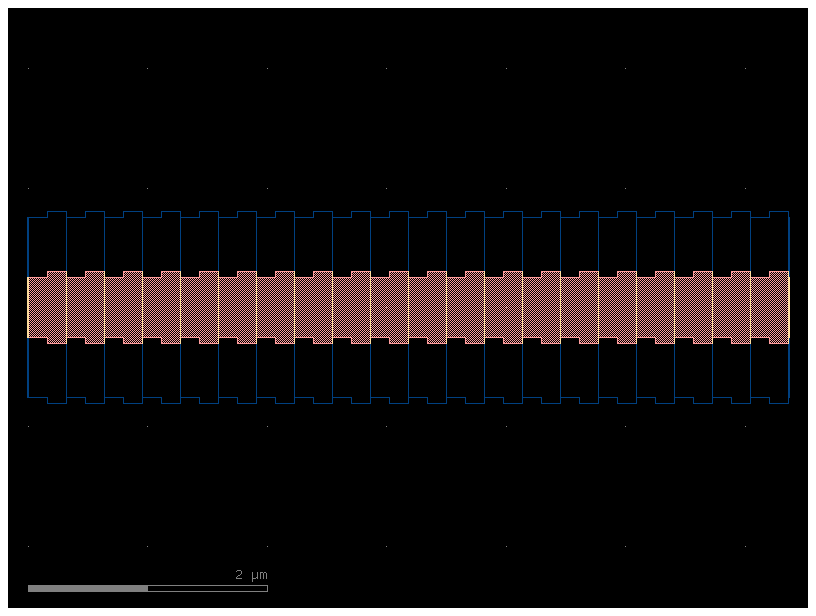

In [14]:
import gdsfactory as gf

dbr = gf.components.dbr(w1=0.5, w2=0.6, n=20)
print(
    "ports:", [port.name for port in dbr.ports], "| size:", dbr.xsize, dbr.ysize, "um"
)
dbr

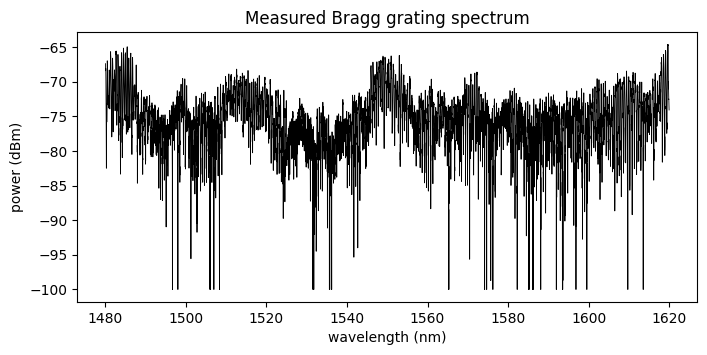

In [15]:
figure, axis = plt.subplots(figsize=(8, 3.5))
try:
    bragg_dat = _fetch.fetch_ubc(_fetch.UBC_BRAGG_MAT)
    wavelength_nm, power_dbm = _fetch.load_ubc_spectrum(bragg_dat)
    axis.plot(wavelength_nm, power_dbm, "k", lw=0.6)
    axis.set(
        title="Measured Bragg grating spectrum",
        xlabel="wavelength (nm)",
        ylabel="power (dBm)",
    )
except _fetch.FetchError as error:
    print("Measured Bragg unavailable:", error)

## Summary

| Case | Geometry present | Reference data present | Notes |
| --- | --- | --- | --- |
| 1. Straight waveguide | yes | yes (SAX) | group index + loss available offline |
| 2. Directional coupler | yes | yes (κ LUT + measured) | measured `opics_ebeam` `.dat` fetched from SiEPIC |
| 3. Ring coupling area | yes | yes (κ LUT) | Cornerstone LUT read directly via xarray |
| 4. MZI | yes | yes (measured + MZI model) | UBC `.mat` fetched from the pinned `gdsfactory/ubc` tree |
| 5. Ring | yes | yes (measured) | radius 10 µm, 100 nm gap |
| 6. Bragg | yes | yes (measured) | CML model in `EBeam.cml` |

Next step: wrap each geometry in `gsim.fdtd.Simulation`, run on
GDSFactory+ FDTD, and compare `result.s_parameters` against these curves.
Port de-embedding for the comparison follows the MEEP
`source_port_offset` convention.